# Simulación multiactivo

Nicole Getzabel Flores Godines

02/11/26

Librerías

In [51]:
import yfinance as yf
import pandas as pd
import numpy as np

**Descarga de datos históricos**

Se descargan los precios históricos de los últimos 3 años de NVIDIA, Bimbo, Cemex y AstraZeneca. Estos datos se utilizarán para calcular los rendimientos y la volatilidad de cada activo.
  

In [52]:
tickers = ["NVDA", "BIMBOA.MX", "CEMEXCPO.MX", "AZN"]
datos = yf.download(
    tickers,
    start="2023-11-02",
    end="2026-11-03",
    auto_adjust=True
)

precios = datos["Close"]

print(precios.head())
print(precios.tail())


[*********************100%***********************]  4 of 4 completed

Ticker             AZN  BIMBOA.MX  CEMEXCPO.MX       NVDA
Date                                                     
2023-11-02  121.751060        NaN          NaN  43.376453
2023-11-03  121.333717  74.936394    11.458241  44.870987
2023-11-06  121.504456  78.346489    11.615203  45.614765
2023-11-07  120.669769  76.946259    11.703496  45.818157
2023-11-08  120.517998  76.241379    11.909508  46.435310
Ticker             AZN  BIMBOA.MX  CEMEXCPO.MX        NVDA
Date                                                      
2026-10-27  170.080002  64.849998    19.730000  217.940002
2026-10-28  169.509995  61.830002    19.700001  215.380005
2026-10-29  174.399994  63.689999    20.480000  213.660004
2026-10-30  186.649994  66.180000    20.230000  204.639999
2026-11-02  186.580002        NaN          NaN  202.059998


**Rendimientos logarítmicos**

Se calculan los rendimientos logarítmicos de los cuatro activos utilizando sus precios históricos. Después se obtiene la media (μ) y la desviación estándar (σ), que servirán para realizar la simulación Monte Carlo.


In [53]:
rendimientos = np.log(precios / precios.shift(1)).dropna()
mu = rendimientos.mean()
sigma = rendimientos.std()

In [54]:
resultados = pd.DataFrame({"Media (μ)": mu,"Volatilidad": sigma
})

print(resultados)

             Media (μ)  Volatilidad
Ticker                             
AZN           0.000654     0.015798
BIMBOA.MX    -0.000211     0.018723
CEMEXCPO.MX   0.000779     0.020797
NVDA          0.002780     0.029463


**Simulación Monte Carlo**

Se simulan los precios futuros de los cuatro activos a un año mediante Monte Carlo, utilizando la media y volatilidad de los rendimientos logarítmicos. Se realizan 10,000 simulaciones para observar los posibles precios futuros.


In [55]:
mu_anual = mu * 252
sigma_anual = sigma * np.sqrt(252)
S0 = np.array([202.06, 66.18, 20.23, 186.58])
T = 1
n_simulaciones = 10000
np.random.seed(42)

In [56]:
orden = ["NVDA", "BIMBOA.MX", "CEMEXCPO.MX", "AZN"]

mu_anual = mu_anual.reindex(orden)
sigma_anual = sigma_anual.reindex(orden)

In [57]:
Z = np.random.normal(size=(n_simulaciones, 4))

ST = S0 * np.exp((mu_anual.values - 0.5 * sigma_anual.values**2) * T
    + sigma_anual.values * np.sqrt(T) * Z)

precios_simulados = pd.DataFrame(ST,columns=["NVDA", "BIMBOA", "CEMEXCPO", "AZN"]
)

print(precios_simulados.head())


         NVDA     BIMBOA   CEMEXCPO         AZN
0  460.365291  57.618379  28.867084  312.372198
1  327.074757  55.999751  39.261130  258.449570
2  292.986807  70.540693  20.002993  189.698637
3  408.654953  33.997542  13.189366  185.160141
4  227.237580  65.912810  17.272226  149.612184


**Cálculo de acciones por escenario**

Se distribuyen los $100,000 MXN entre los cuatro activos según los pesos de los escenarios A, B y C. Se convierten los precios en dólares a pesos y se calcula la cantidad de acciones que corresponde a cada inversión.


In [58]:
V0 = 100000
TC = 18.58
S0_MXN = S0 * np.array([TC, 1, 1, TC])

In [59]:
escenarios = {
    "A": [1, 0, 0, 0],
    "B": [0.25, 0.25, 0.25, 0.25],
    "C": [0.10, 0.20, 0.30, 0.40]
}

acciones = {}
cambios = {}

for nombre, pesos in escenarios.items():
    Ni = np.floor((V0 * np.array(pesos)) / S0_MXN).astype(int)

    acciones[nombre] = Ni

    cambios[nombre] = V0 - np.sum(Ni * S0_MXN)

tabla_acciones = pd.DataFrame(
    acciones,
    index=["NVDA", "BIMBOA", "CEMEXCPO", "AZN"]
).T

tabla_acciones["Cambio (MXN)"] = pd.Series(cambios).round(2)

display(tabla_acciones)


,NVDA,BIMBOA,CEMEXCPO,AZN,Cambio (MXN)
A,26,0,0,0,2388.86
B,6,377,1235,7,3273.85
C,2,302,1482,11,4391.01


**Valor final del portafolio**

Se calcula el valor futuro del portafolio para los escenarios A, B y C, utilizando las acciones adquiridas y los precios simulados. Después se obtiene el valor promedio, la ganancia o pérdida y el rendimiento de cada escenario para compararlos.


In [60]:
ST_MXN = ST * np.array([TC, 1, 1, TC])

valores_finales = pd.DataFrame()

for nombre, Ni in acciones.items():
    valores_finales[nombre] = ST_MXN @ Ni

comparacion = pd.DataFrame({
    "Valor promedio final": valores_finales.mean(),
    "Ganancia/Pérdida": valores_finales.mean() - V0,
    "Rendimiento (%)": (valores_finales.mean() / V0 - 1) * 100
})

print(comparacion.round(2))

   Valor promedio final  Ganancia/Pérdida  Rendimiento (%)
A             197421.72          97421.72            97.42
B             128104.69          28104.69            28.10
C             115475.86          15475.86            15.48


**Histogramas y comparación de escenarios**

Se elaboran histogramas del valor final de los tres portafolios para observar su distribución. Después, se realizan comparaciones estadísticas entre A, B y C utilizando un nivel de significancia alfa.


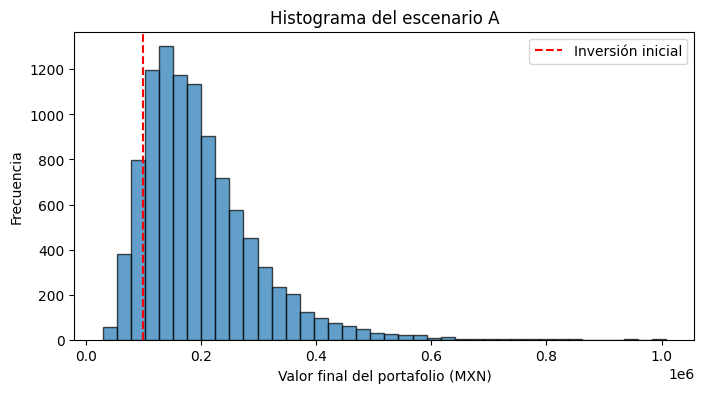

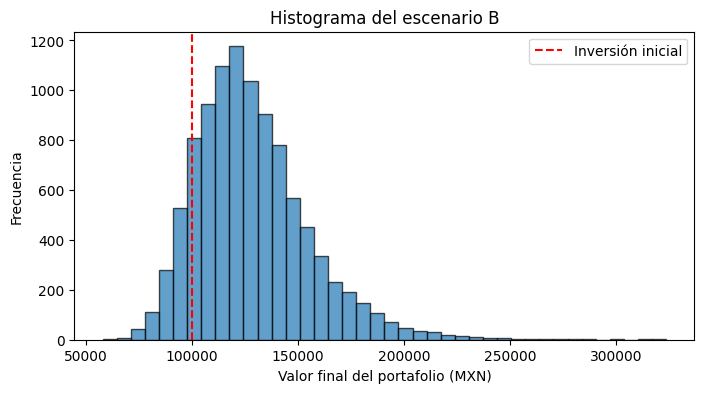

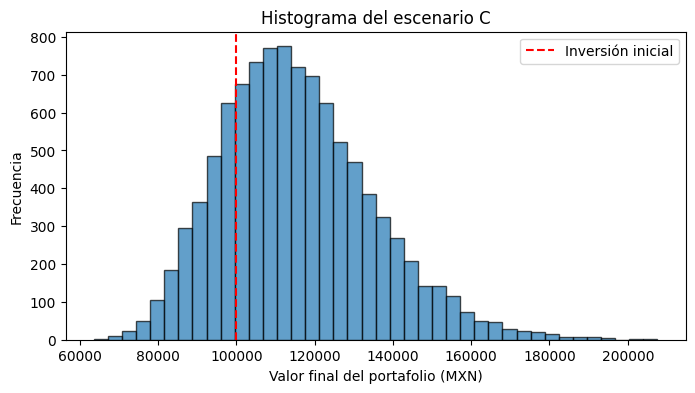

In [61]:
import matplotlib.pyplot as plt

for escenario in ["A", "B", "C"]:
    plt.figure(figsize=(8, 4))
    plt.hist(valores_finales[escenario], bins=40,
             edgecolor="black", alpha=0.7)
    plt.axvline(V0, color="red", linestyle="--",
                label="Inversión inicial")
    plt.title(f"Histograma del escenario {escenario}")
    plt.xlabel("Valor final del portafolio (MXN)")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.show()


**Comparación estadística de escenarios**

Se comparan los valores finales de los tres portafolios para determinar si existen diferencias significativas entre sus rendimientos simulados, utilizando un nivel de significancia del 5%.


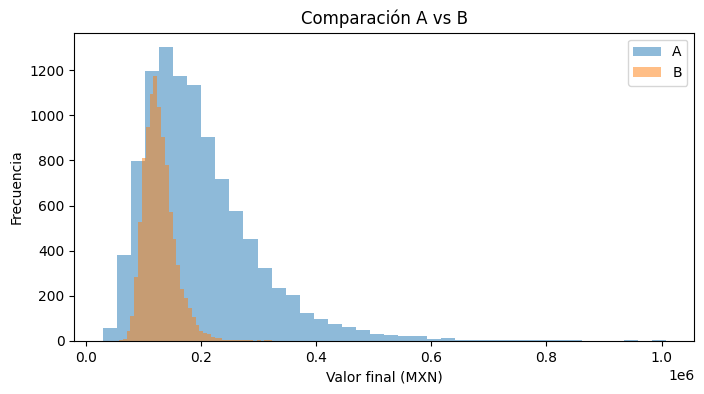

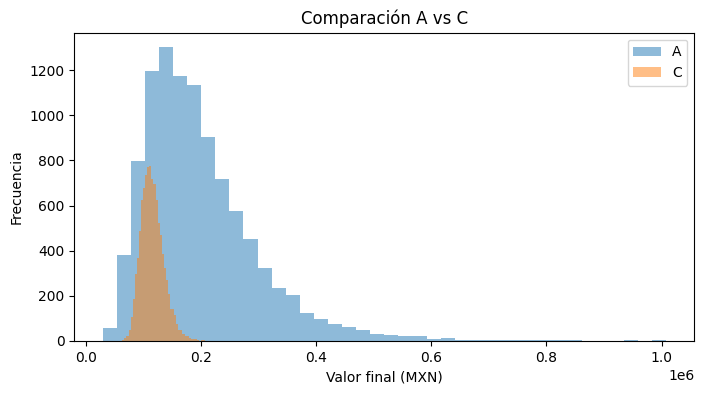

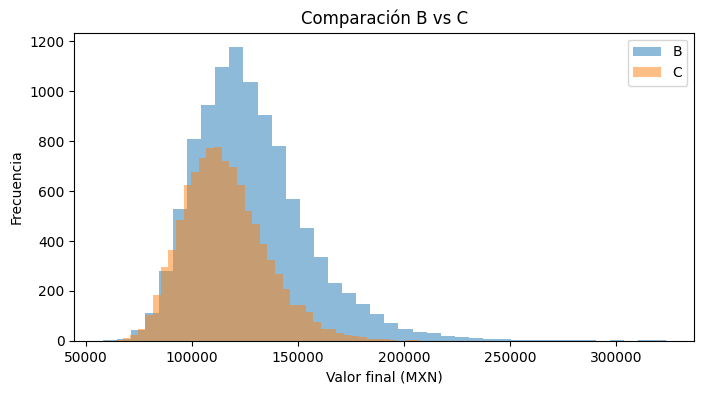

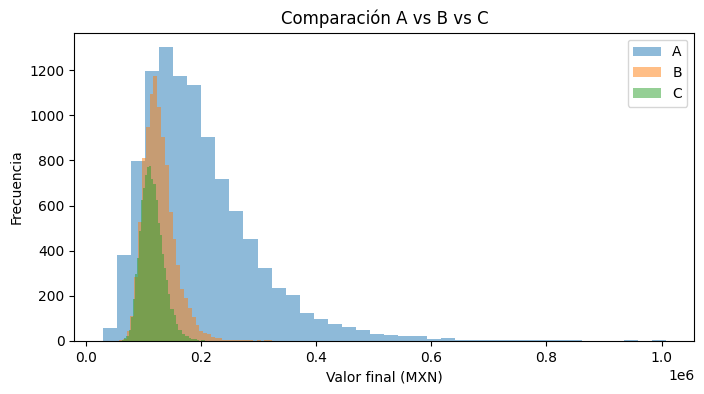

In [62]:
comparaciones = [
    ["A", "B"],
    ["A", "C"],
    ["B", "C"],
    ["A", "B", "C"]
]

for grupo in comparaciones:
    plt.figure(figsize=(8, 4))

    for escenario in grupo:
        plt.hist(valores_finales[escenario],
                 bins=40, alpha=0.5,
                 label=escenario)

    plt.title("Comparación " + " vs ".join(grupo))
    plt.xlabel("Valor final (MXN)")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.show()


**Independencia vs. correlación**

Se repiten los tres escenarios de inversión con $100,000 MXN, considerando ahora la correlación entre NVIDIA, Bimbo, Cemex y AstraZeneca mediante Cholesky.

In [63]:
orden_A = ["NVDA", "BIMBOA.MX", "CEMEXCPO.MX", "AZN"]
r_A = rendimientos[orden_A]
mu_A = r_A.mean().values * 252
sigma_A = r_A.std().values * np.sqrt(252)
S0_A = np.array([202.06, 66.18, 20.23, 186.58])
corr_A = r_A.corr()
L_A = np.linalg.cholesky(corr_A.values)


In [64]:
np.random.seed(42)
Z_ind = np.random.normal(size=(n_simulaciones, 4))
Z_corr = Z_ind @ L_A.T

In [65]:
ST_ind = S0_A * np.exp(
    (mu_A - 0.5 * sigma_A**2) * T
    + sigma_A * np.sqrt(T) * Z_ind
)

ST_corr = S0_A * np.exp(
    (mu_A - 0.5 * sigma_A**2) * T
    + sigma_A * np.sqrt(T) * Z_corr
)

conversion_A = np.array([TC, 1, 1, TC])

ST_ind_MXN = ST_ind * conversion_A
ST_corr_MXN = ST_corr * conversion_A

In [66]:
valores_A = {}

for tipo, precios_A in {
    "Independiente": ST_ind_MXN,
    "Correlacionado": ST_corr_MXN
}.items():

    valores_A[tipo] = pd.DataFrame({
        caso: precios_A @ acciones[caso] + cambios[caso]
        for caso in ["A", "B", "C"]
    })

print("Matriz de correlación:")
display(corr_A.round(4))

print("Primeros valores de la simulación correlacionada:")
display(valores_A["Correlacionado"].head())


Matriz de correlación:


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN
Ticker,,,,
NVDA,1.0000,0.0877,0.2426,-0.0017
BIMBOA.MX,0.0877,1.0000,0.2113,0.1080
CEMEXCPO.MX,0.2426,0.2113,1.0000,0.0976
AZN,-0.0017,0.1080,0.0976,1.0000


Primeros valores de la simulación correlacionada:


,A,B,C
0,224782.120096,153857.654968,147009.065448
1,160392.128704,140871.869732,142324.746936
2,143924.922026,111829.162250,105101.078838
3,199801.889679,98991.599443,82820.192461
4,112162.785546,92494.487432,87031.912325


**Comparación de resultados**

Se comparan el valor promedio, rendimiento, desviación estándar y probabilidad de pérdida de los tres escenarios, utilizando simulaciones independientes y correlacionadas.

In [73]:
resultados = []

for tipo, tabla in valores_A.items():
    for escenario in ["A", "B", "C"]:

        valores = tabla[escenario]

        resultados.append({
            "Simulación": tipo,
            "Escenario": escenario,
            "Valor promedio (MXN)": valores.mean(),
            "Rendimiento (%)": (valores.mean() / V0 - 1) * 100,
            "Desviación estándar": valores.std(),
            "Probabilidad de pérdida (%)": (valores < V0).mean() * 100
        })

comparacion_A = pd.DataFrame(resultados)

display(comparacion_A.round(2))

,Simulación,Escenario,Valor promedio (MXN),Rendimiento (%),Desviación estándar,Probabilidad de pérdida (%)
0,Independiente,A,199810.58,99.81,97809.08,10.28
1,Independiente,B,131378.53,31.38,26830.96,8.76
2,Independiente,C,119866.87,19.87,19460.51,14.62
3,Correlacionado,A,199810.58,99.81,97809.08,10.28
4,Correlacionado,B,131368.91,31.37,30130.96,12.60
5,Correlacionado,C,119851.07,19.85,22288.36,18.56


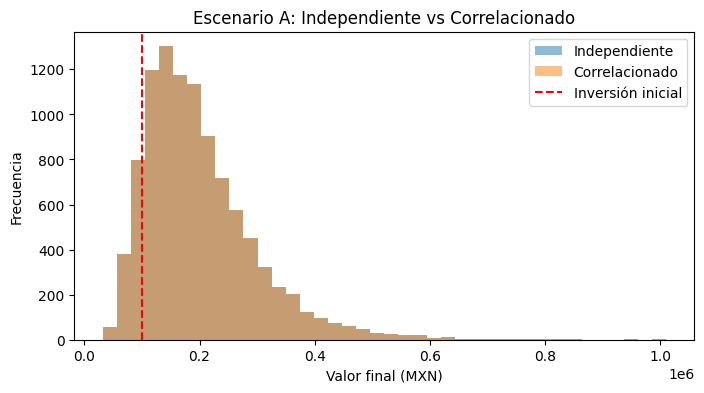

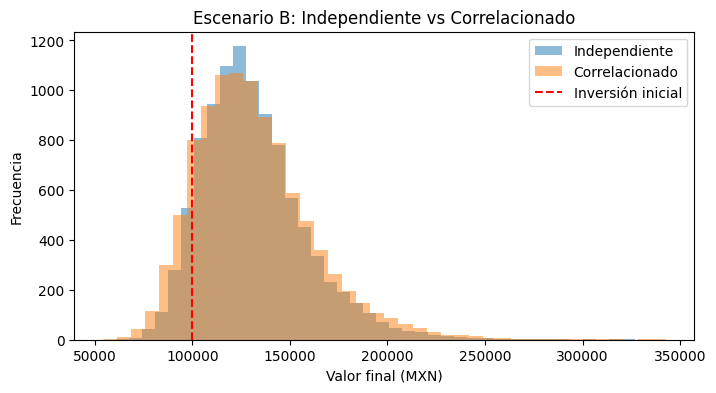

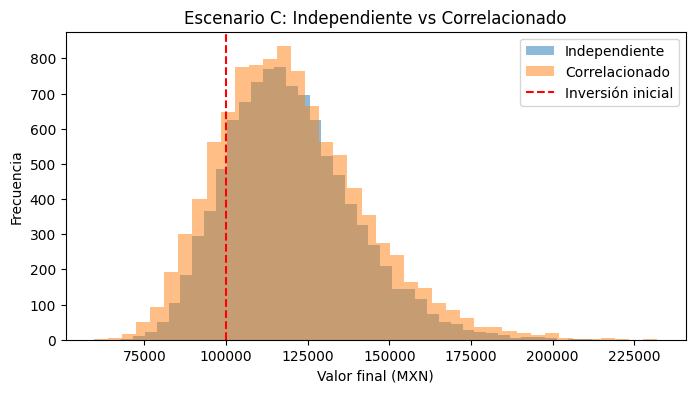

In [74]:

for escenario in ["A", "B", "C"]:

    plt.figure(figsize=(8, 4))

    plt.hist(valores_A["Independiente"][escenario],
             bins=40, alpha=0.5, label="Independiente")

    plt.hist(valores_A["Correlacionado"][escenario],
             bins=40, alpha=0.5, label="Correlacionado")

    plt.axvline(V0, color="red", linestyle="--",
                label="Inversión inicial")

    plt.title(f"Escenario {escenario}: Independiente vs Correlacionado")
    plt.xlabel("Valor final (MXN)")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.show()



## Conclusión

En esta actividad se realizó una simulación Monte Carlo utilizando los precios históricos de NVIDIA, Bimbo, Cemex y AstraZeneca de los últimos tres años. Se calcularon los rendimientos logarítmicos, la media y la volatilidad para simular los precios futuros. Después, se distribuyeron $100,000 MXN en tres escenarios con diferentes porcentajes de inversión, considerando las acciones compradas y el dinero sobrante. Finalmente, mediante los histogramas y las comparaciones estadísticas, se buscó identificar qué escenario ofrece un mayor valor final y cómo cambia el riesgo dependiendo de la distribución del dinero. Esto nos permite entender la importancia de diversificar un portafolio y comparar diferentes estrategias de inversión.




# Parte 2. Correlación entre los activos

En esta segunda parte se calcula la correlación entre los rendimientos de los activos, para identificar qué tan relacionados están sus movimientos y analizar la diversificación del portafolio.


In [67]:
tickers = ["AAPL", "MSFT", "NVDA"]
datos_2 = yf.download(tickers,period="3y",auto_adjust=True)
precios_2 = datos_2["Close"]

[*********************100%***********************]  3 of 3 completed


In [68]:
rendimientos_2 = np.log(precios_2 / precios_2.shift(1)).dropna()

correlacion_2 = rendimientos_2.corr()
display(correlacion_2.round(4))
covarianza_2 = rendimientos_2.cov()


Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.0000,0.3412,0.2745
MSFT,0.3412,1.0000,0.4089
NVDA,0.2745,0.4089,1.0000


**Descomposición de L**

Se aplica la descomposición de Cholesky a la matrz de correlación para obtener una matriz triangular inferior, que permitirá generar rendimientos aleatorios correlacionados entre los tres activos.

In [69]:
L = np.linalg.cholesky(covarianza_2)

print("Matriz L (Cholesky):")
print(np.round(L, 4))


Matriz L (Cholesky):
[[0.0169 0.     0.    ]
 [0.0057 0.0156 0.    ]
 [0.0082 0.01   0.0268]]


**Simulación de valores aleatorios**

Se generan 10,000 simulaciones de números aleatorios con distribución normal estándar para los tres activos. Estos valores se utilizarán para incorporar la correlación mediante la matriz de Cholesky.


In [70]:
np.random.seed(42)
n= 10000
epsilon = np.random.normal(0, 1, size=(n, 3))

print("Valores aleatorios:")
print(np.round(epsilon[:5], 4))


Valores aleatorios:
[[ 0.4967 -0.1383  0.6477]
 [ 1.523  -0.2342 -0.2341]
 [ 1.5792  0.7674 -0.4695]
 [ 0.5426 -0.4634 -0.4657]
 [ 0.242  -1.9133 -1.7249]]


**Transformación de valores aleatorios**

Se multiplican los valores aleatorios por la matriz de Cholesky para obtener simulaciones correlacionadas. Esto permite que los movimientos simulados de los tres activos mantengan una relación similar a la observada en los datos históricos.


In [71]:
Z = epsilon @ L.T
Z_df = pd.DataFrame(Z,columns=["AAPL", "MSFT", "NVDA"])

print("Valores aleatorios correlacionados (Z):")
display(Z_df.head())

Valores aleatorios correlacionados (Z):


,AAPL,MSFT,NVDA
0,0.008410,0.000658,0.020004
1,0.025787,0.004986,0.003819
2,0.026738,0.020974,0.007954
3,0.009186,-0.004169,-0.012654
4,0.004097,-0.028558,-0.063238


In [72]:
S0 = precios_2.dropna().iloc[-1].reindex(["AAPL", "MSFT", "NVDA"]).values
mu = rendimientos_2.mean().reindex(["AAPL", "MSFT", "NVDA"]).values * 252
sigma = rendimientos_2.std().reindex(["AAPL", "MSFT", "NVDA"]).values * np.sqrt(252)
T = 1

ST = S0 * np.exp(
        (mu - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z
    )
tabla_ST = pd.DataFrame(ST, columns=["AAPL", "MSFT", "NVDA"])
tabla_ST.head()

,AAPL,MSFT,NVDA
0,428.446097,569.324298,243.293068
1,430.451783,569.975713,241.444084
2,430.561850,572.388512,241.915161
3,428.535492,568.598764,239.576600
4,427.949695,564.946591,233.931966


**Inversión independiente vs. correlacionada**

Se distribuyen $100,000 MXN entre Apple, Microsoft y NVIDIA utilizando tres esquemas de inversión. Se calcula la cantidad de acciones compradas y el efectivo restante para posteriormente comparar las simulaciones independientes y correlacionadas.

In [75]:
V0_B = 100000
TC_B = TC
activos_B = ["AAPL", "MSFT", "NVDA"]

S0_B = precios_2[activos_B].dropna().iloc[-1].values
S0_B_MXN = S0_B * TC_B

escenarios_B = {
    "Caso 1": [1, 0, 0],
    "Caso 2": [0.33, 0.33, 0.34],
    "Caso 3": [0.2, 0.2, 0.6]
}

acciones_B = {}
cambios_B = {}

for caso, pesos in escenarios_B.items():

    Ni = np.floor(
        (V0_B * np.array(pesos)) / S0_B_MXN
    ).astype(int)

    acciones_B[caso] = Ni

    cambios_B[caso] = V0_B - np.sum(Ni * S0_B_MXN)

In [76]:
tabla_B = pd.DataFrame(
    acciones_B, index=activos_B
).T

tabla_B["Efectivo restante (MXN)"] = pd.Series(cambios_B).round(2)

display(tabla_B)


,AAPL,MSFT,NVDA,Efectivo restante (MXN)
Caso 1,15,0,0,1152.08
Caso 2,5,3,10,5533.82
Caso 3,3,2,18,2358.33


**Simulación Monte Carlo independiente y correlacionada**

Se realizan 10,000 simulaciones a un año. Se utiliza Cholesky para incorporar la correlación entre los activos y comparar los resultados con una simulación independiente.

In [77]:
activos_B = ["AAPL", "MSFT", "NVDA"]

r_B = rendimientos_2[activos_B]

mu_B = r_B.mean().values * 252
sigma_B = r_B.std().values * np.sqrt(252)

cov_B = r_B.cov().values
L_B = np.linalg.cholesky(cov_B)

np.random.seed(42)
epsilon_B = np.random.normal(
    size=(n_simulaciones, 3)
)

ST_ind_B = S0_B * np.exp(
    (mu_B - 0.5 * sigma_B**2) * T
    + sigma_B * np.sqrt(T) * epsilon_B
)

Z_corr_B = epsilon_B @ L_B.T

ST_corr_B = S0_B * np.exp(
    (mu_B - 0.5 * sigma_B**2) * T
    + Z_corr_B * np.sqrt(252 * T)
)

valores_B = {}

for tipo, precios_B in {
    "Independiente": ST_ind_B,
    "Correlacionado": ST_corr_B
}.items():

    valores_B[tipo] = pd.DataFrame({
        caso: (precios_B * TC_B) @ acciones_B[caso]
        + cambios_B[caso]
        for caso in escenarios_B
    })

print("Simulación independiente:")
display(valores_B["Independiente"].head())

print("Simulación correlacionada:")
display(valores_B["Correlacionado"].head())


Simulación independiente:


,Caso 1,Caso 2,Caso 3
0,137306.356958,142276.015700,159363.352770
1,180555.079735,135260.650730,130303.497427
2,183284.706312,140995.402916,129294.181396
3,138994.448309,115507.105944,113358.069473
4,128295.810542,86913.792353,76294.080088


Simulación correlacionada:


,Caso 1,Caso 2,Caso 3
0,137306.356958,144496.371888,161692.694538
1,180555.079735,147254.925426,146774.215455
2,183284.706312,161315.120434,159745.494728
3,138994.448309,117808.267477,115658.940291
4,128295.810542,84488.369355,70767.142513


**Comparación de resultados independientes y correlacionados**

Se comparan el valor promedio, rendimiento, desviación estándar y probabilidad de pérdida de los tres portafolios para identificar el efecto de la correlación entre los activos.

In [78]:
resultados_B = []

for tipo, tabla in valores_B.items():

    for caso in ["Caso 1", "Caso 2", "Caso 3"]:

        valores = tabla[caso]

        resultados_B.append({
            "Simulación": tipo,
            "Portafolio": caso,
            "Valor promedio (MXN)": valores.mean(),
            "Rendimiento (%)": (valores.mean() / V0_B - 1) * 100,
            "Desviación estándar": valores.std(),
            "Probabilidad de pérdida (%)": (valores < V0_B).mean() * 100
        })

comparacion_B = pd.DataFrame(resultados_B)

display(comparacion_B.round(2))

,Simulación,Portafolio,Valor promedio (MXN),Rendimiento (%),Desviación estándar,Probabilidad de pérdida (%)
0,Independiente,Caso 1,124513.94,24.51,33875.32,24.88
1,Independiente,Caso 2,129541.55,29.54,28450.14,12.10
2,Independiente,Caso 3,138965.44,38.97,45401.75,17.25
3,Correlacionado,Caso 1,124513.94,24.51,33875.32,24.88
4,Correlacionado,Caso 2,129460.56,29.46,34412.91,18.80
5,Correlacionado,Caso 3,138847.79,38.85,49266.71,20.98


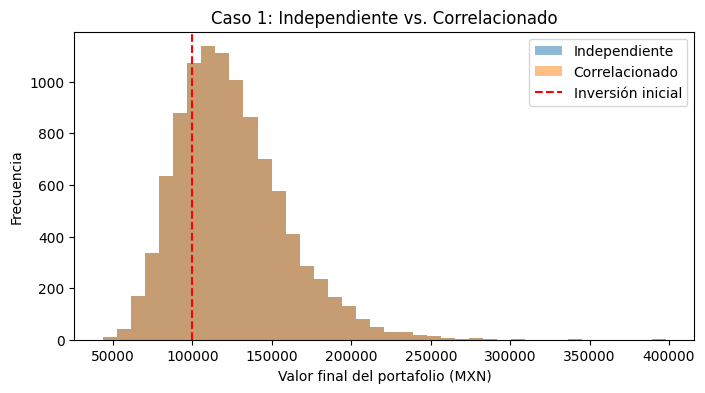

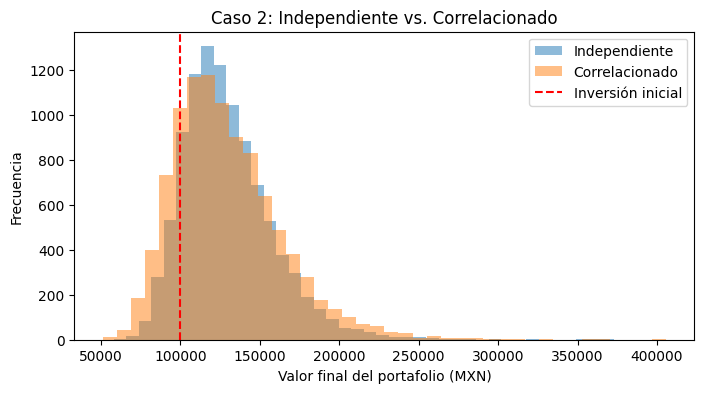

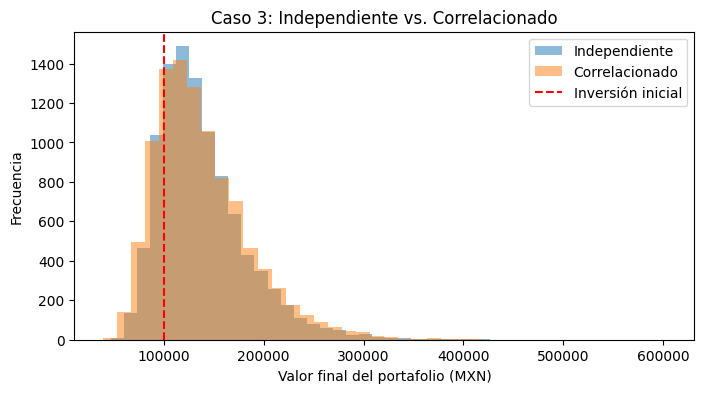

In [79]:
for caso in ["Caso 1", "Caso 2", "Caso 3"]:

    independiente = valores_B["Independiente"][caso]
    correlacionado = valores_B["Correlacionado"][caso]

    plt.figure(figsize=(8, 4))

    plt.hist(independiente, bins=40, alpha=0.5,
             label="Independiente")

    plt.hist(correlacionado, bins=40, alpha=0.5,
             label="Correlacionado")

    plt.axvline(V0_B, color="red", linestyle="--",
                label="Inversión inicial")

    plt.title(f"{caso}: Independiente vs. Correlacionado")
    plt.xlabel("Valor final del portafolio (MXN)")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.show()



## Conclusión

En esta actividad aprendí a calcular la correlación entre Apple, Microsoft y NVIDIA para conocer cómo se relacionan sus rendimientos. Después, utilicé la descomposición de Cholesky y generé 10,000 simulaciones aleatorias para obtener valores correlacionados. Con esto pude entender cómo tomar en cuenta la relación entre diferentes activos al realizar simulaciones financieras.
